# Forecasting India's CPI Inflation: SARIMA vs Machine Learning

Can machine-learning models forecast India's headline CPI inflation better than a classical seasonal ARIMA model and a simple no-change benchmark?

**Data:** MOSPI Consumer Price Index (base 2012), All-India, Combined (rural + urban), January 2013 to January 2025.  
**Target:** year-on-year headline inflation, forecast 1, 3 and 6 months ahead.  
**Evaluation:** expanding-window pseudo out-of-sample backtest, 49 forecasts per horizon (targets January 2021 to January 2025), RMSE, MAE and Diebold-Mariano tests.

In [1]:
import sys; sys.path.insert(0, '../src')
import pandas as pd
from IPython.display import Image, display
from data import build_panel
from evaluate import run_backtest, score, score_by_period
pd.set_option('display.precision', 3)

## 1. Data

The panel is built from MOSPI's group-level indices. Headline inflation is recomputed from the index and checked against MOSPI's published rate (maximum gap under 0.01 percentage points). Food inflation uses the Consumer Food Price Index (CFPI).

In [2]:
panel = build_panel()
print(f'{len(panel)} months: {panel.index.min():%b %Y} to {panel.index.max():%b %Y}')
panel[['cpi_general', 'infl_general', 'inflation_official', 'infl_food']].tail(6)

145 months: Jan 2013 to Jan 2025


,cpi_general,infl_general,inflation_official,infl_food
date,,,,
2024-08-01,193.0,3.652,3.65,5.662
2024-09-01,194.2,5.486,5.49,9.236
2024-10-01,196.8,6.206,6.21,10.872
2024-11-01,196.5,5.475,5.48,9.044
2024-12-01,195.4,5.223,5.22,8.390
2025-01-01,193.5,4.313,4.31,6.022


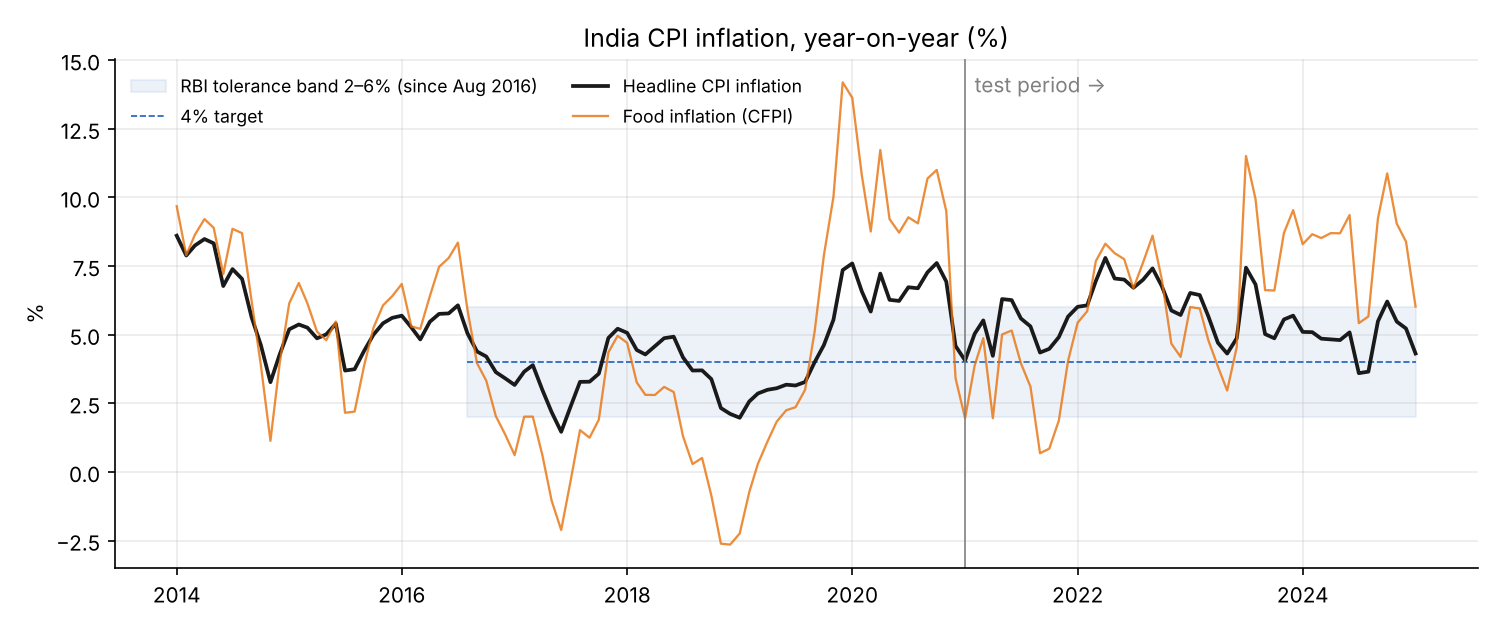

In [3]:
display(Image('../figures/01_inflation_history.png'))

## 2. Models

| Model | Idea |
|---|---|
| Random walk | Inflation in *h* months equals inflation today (the benchmark to beat) |
| SARIMA | Seasonal ARIMA on log CPI; order chosen by AIC on pre-2021 data only, re-estimated at every origin |
| Ridge | Penalised linear regression on 12 lags of headline inflation, food, fuel and miscellaneous inflation, month-on-month momentum and target-month dummies |
| Random Forest | Same predictors, 500 trees |
| Gradient Boosting | Same predictors, shallow trees (depth 2) |
| Average of models | Equal-weight mean of the four non-naive models, fixed in advance |

ML models are *direct*: one model per horizon, refit at every forecast origin using only data available at that date. `tests/test_no_lookahead.py` checks this.

## 3. Backtest

Runs in about 3 minutes.

In [4]:
fc, info = run_backtest(panel)
print('SARIMA order:', info['sarima_order'], info['sarima_seasonal_order'])
scores = score(fc)
scores.pivot_table(index='model', columns='horizon', values='relative RMSE vs random walk')

SARIMA order: (0, 1, 1) (0, 1, 1, 12)


horizon,1,3,6
model,,,
Average of models,0.903,0.909,1.072
Gradient Boosting,1.066,1.134,1.337
Random Forest,1.065,1.016,1.179
Random walk,1.000,1.000,1.000
Ridge,1.130,1.124,1.487
SARIMA,0.671,0.751,0.741


In [5]:
scores.round(3)

,horizon,model,n,RMSE,MAE,relative RMSE vs random walk,DM p-value vs random walk
0,1,Random walk,49,0.843,0.631,1.000,NaN
1,1,SARIMA,49,0.565,0.401,0.671,0.002
2,1,Ridge,49,0.952,0.742,1.130,0.097
3,1,Random Forest,49,0.897,0.723,1.065,0.393
4,1,Gradient Boosting,49,0.899,0.667,1.066,0.400
5,1,Average of models,49,0.761,0.573,0.903,0.136
6,3,Random walk,49,1.379,1.103,1.000,NaN
7,3,SARIMA,49,1.036,0.796,0.751,0.011
8,3,Ridge,49,1.550,1.333,1.124,0.460
9,3,Random Forest,49,1.401,1.170,1.016,0.930


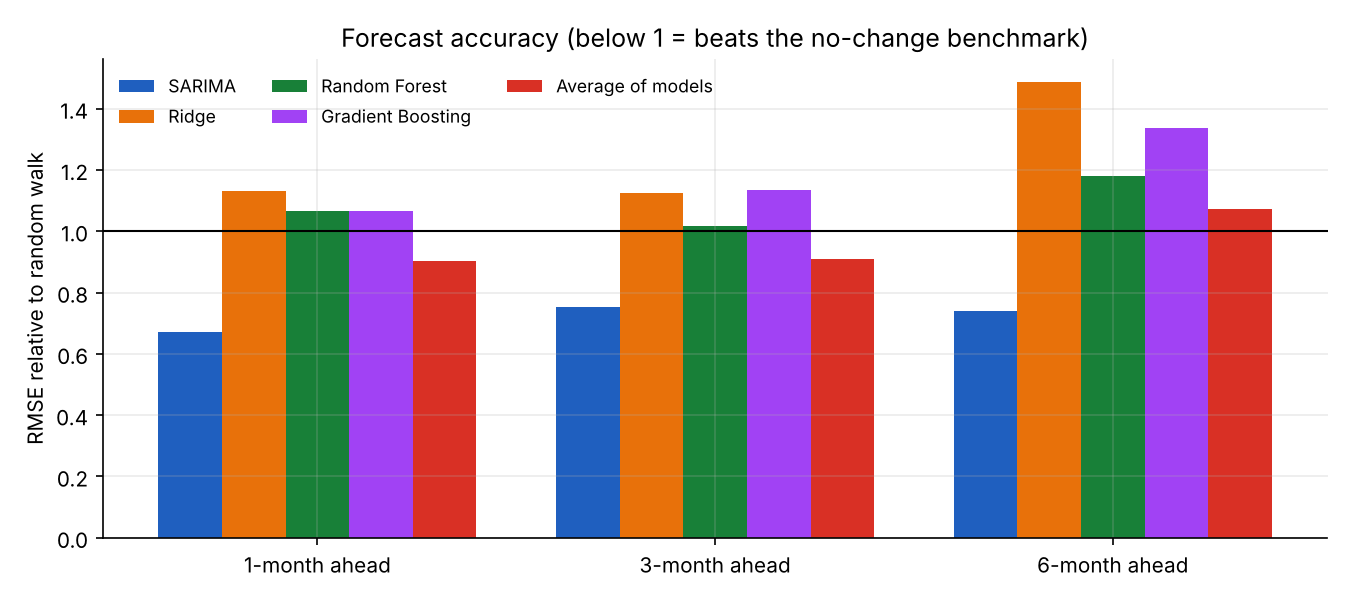

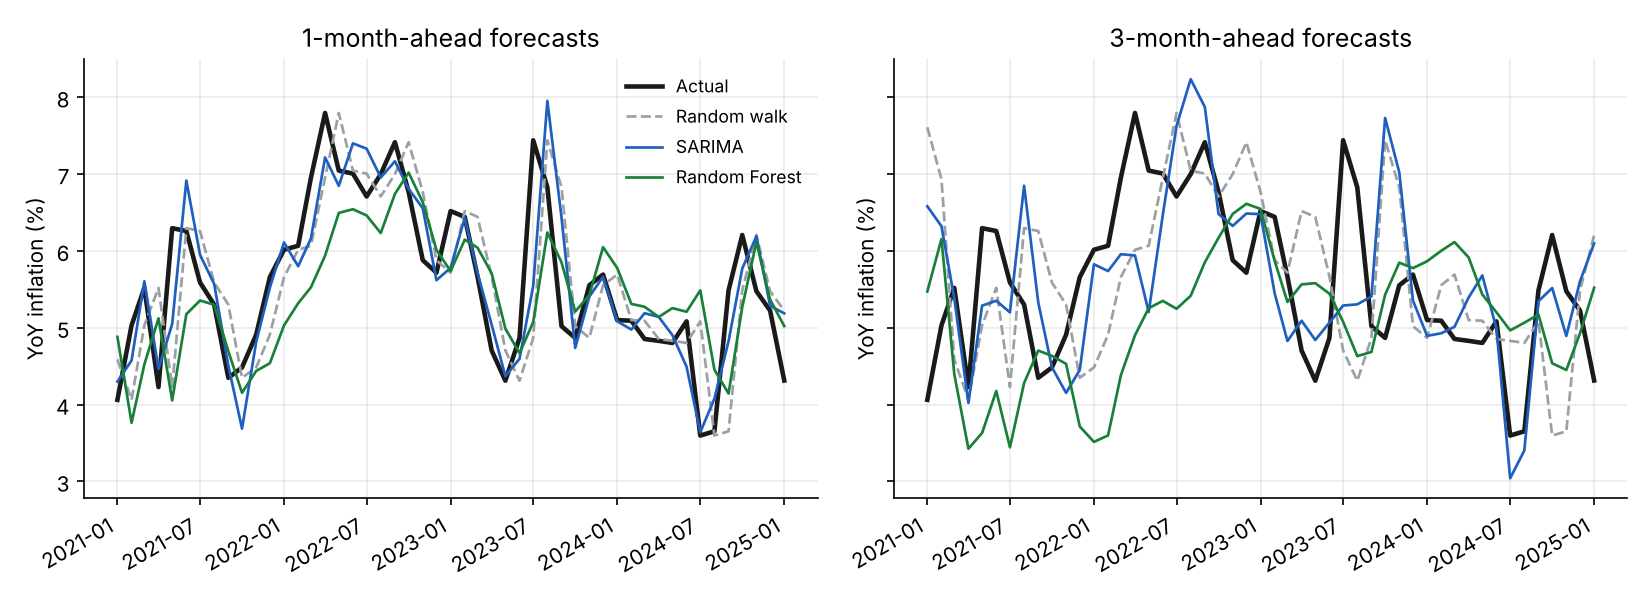

In [6]:
display(Image('../figures/03_relative_rmse.png'))
display(Image('../figures/02_forecasts_vs_actual.png'))

## 4. Does it depend on the period?

In [7]:
score_by_period(fc)

horizon                                          1      3      6
period                    model                                 
2021-22 (inflation surge) Average of models  0.777  1.446  1.985
                          Gradient Boosting  0.946  1.860  2.421
                          Random Forest      0.944  1.685  2.180
                          Random walk        0.746  1.351  1.636
                          Ridge              1.024  1.799  2.748
                          SARIMA             0.472  1.064  1.200
2023-25 (disinflation)    Average of models  0.746  1.034  0.787
                          Gradient Boosting  0.850  1.212  1.104
                          Random Forest      0.850  1.058  0.873
                          Random walk        0.926  1.405  1.124
                          Ridge              0.877  1.267  1.105
                          SARIMA             0.642  1.009  0.848

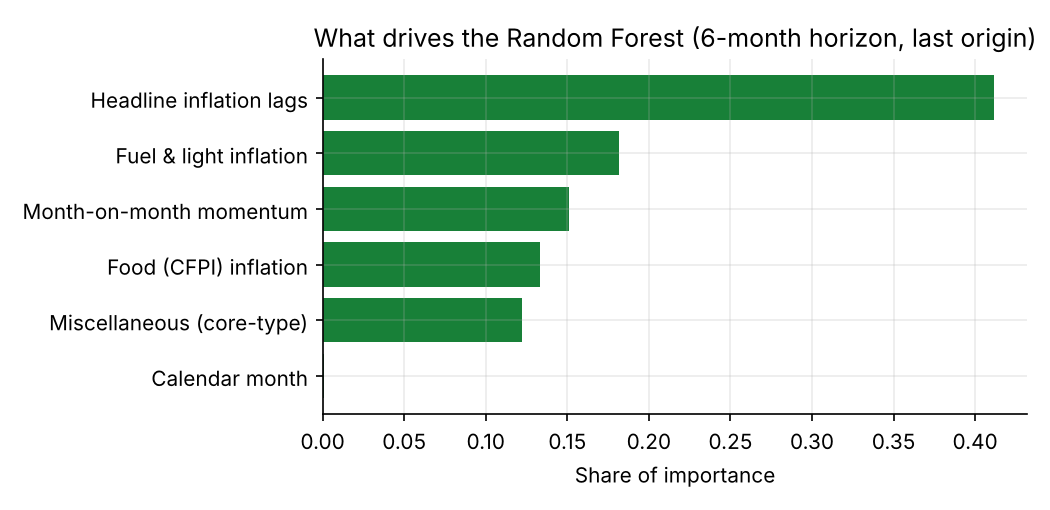

In [8]:
display(Image('../figures/04_rf_feature_importance.png'))

## 5. Findings

1. **SARIMA is the most accurate model at every horizon**, cutting RMSE by 25-33% relative to the no-change benchmark; the gain is statistically significant (Diebold-Mariano p < 0.02 at all horizons).
2. **Machine-learning models do not beat the benchmark over the full test period.** With only 60-120 monthly training observations and around 40 predictors, they overfit, and they lag turning points such as the 2022 surge.
3. **The picture improves as the training sample grows.** In the 2023-25 disinflation period, the Random Forest and the model average beat the benchmark at the 6-month horizon, and the average edges out SARIMA there.
4. **Why SARIMA works:** year-on-year inflation is largely mechanical. Next month's rate depends on the price level 11 months earlier, which is already known (the *base effect*), plus a seasonal pattern. A model of the price level captures this directly; a model of the inflation rate must learn it.

**Limitations and next steps:** single test window; no external drivers (crude oil prices, monsoon rainfall, exchange rate, RBI policy rate); data end in January 2025, before the new CPI series (base 2024). Natural extensions are adding these drivers, a SARIMA + ML hybrid that models SARIMA's residuals, and density (fan-chart) forecasts as used in RBI's Monetary Policy Report.